# Analysis of In-Demand Skills in Computer Science Job Postings
**Dataset:** `data/computer_science_jobs_cleaned.xlsx` — 25,909 job postings | 10 CS roles | 139 countries | January 2024

### Research Question
> *"If someone wants a career in Computer Science, what skills should they learn first?"*

### Analyses
1. Job Postings by Title
2. Top 15 Skills Overall
3. Top Skills by Job Title
4. Skill Categories
5. Skills by Country
6. Average Salary by Job Title
7. Salary by Skill
8. Job Posting Trend Over Time
9. Skill Importance Ranking
10. Average Skills Required per Job
11. Word Cloud

---
## ⚙️ Setup — Import Libraries

In [ ]:
import pandas as pd
import ast
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.dates as mdates
from collections import Counter
import warnings
warnings.filterwarnings('ignore')

%matplotlib inline
plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#E2E8F0',
    'grid.linewidth': 0.6,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
})

# Colour palette
NAVY  = '#1E3A5F'
BLUE  = '#2563EB'
TEAL  = '#0D9488'
AMBER = '#D97706'
ROSE  = '#E11D48'
SLATE = '#475569'
WHITE = '#FFFFFF'
PALETTE = [BLUE, '#4F46E5', TEAL, AMBER, ROSE, '#7C3AED', '#059669', '#DC2626', '#0891B2', '#65A30D']

print('✅ Libraries loaded successfully')

✅ Libraries loaded successfully


---
##  Step 1 — Load & Clean the Data

In [ ]:
import pandas as pd
import ast


# Load the dataset
df_raw = pd.read_excel('data/computer_science_jobs_cleaned.xlsx')

# Parse skills from string format ['python','sql'] into actual Python lists
def parse_skills(raw):
    if pd.isna(raw):
        return []
    try:
        return [skill.strip().lower() for skill in ast.literal_eval(raw)]
    except:
        return []

df_raw['skills_list'] = df_raw['job_skills'].apply(parse_skills)

# Keep only rows with skills
df = df_raw[df_raw['skills_list'].map(len) > 0].copy()

# Separate rows that have salary data
df_sal = df[df['salary_year_avg'].notna()].copy()

# Flatten all skills into one big list
all_skills = [sk for lst in df['skills_list'] for sk in lst]

print('=' * 45)
print('  Dataset Summary')
print('=' * 45)
print(f'Total job postings:       {len(df_raw):>7,}')
print(f'Rows with skills data:    {len(df):>7,}')
print(f'Rows with salary data:    {len(df_sal):>7,}')
print(f'Unique job titles:        {df["job_title_short"].nunique():>7}')
print(f'Unique countries:         {df["job_country"].nunique():>7}')
print(f'Unique skills found:      {len(set(all_skills)):>7}')
print('=' * 45)
print()
print('Job postings by title:')
print(df_raw['job_title_short'].value_counts().to_string())

  Dataset Summary
Total job postings:        25,909
Rows with skills data:     25,909
Rows with salary data:      1,570
Unique job titles:             10
Unique countries:             139
Unique skills found:          232

Job postings by title:
job_title_short
Data Analyst                 9913
Data Scientist               9765
Software Engineer            2302
Senior Data Scientist        2186
Senior Data Analyst          1392
Data Engineer                 190
Machine Learning Engineer      90
Senior Data Engineer           38
Cloud Engineer                 21
Business Analyst               12


---
##  Analysis 1 — Job Postings by Title

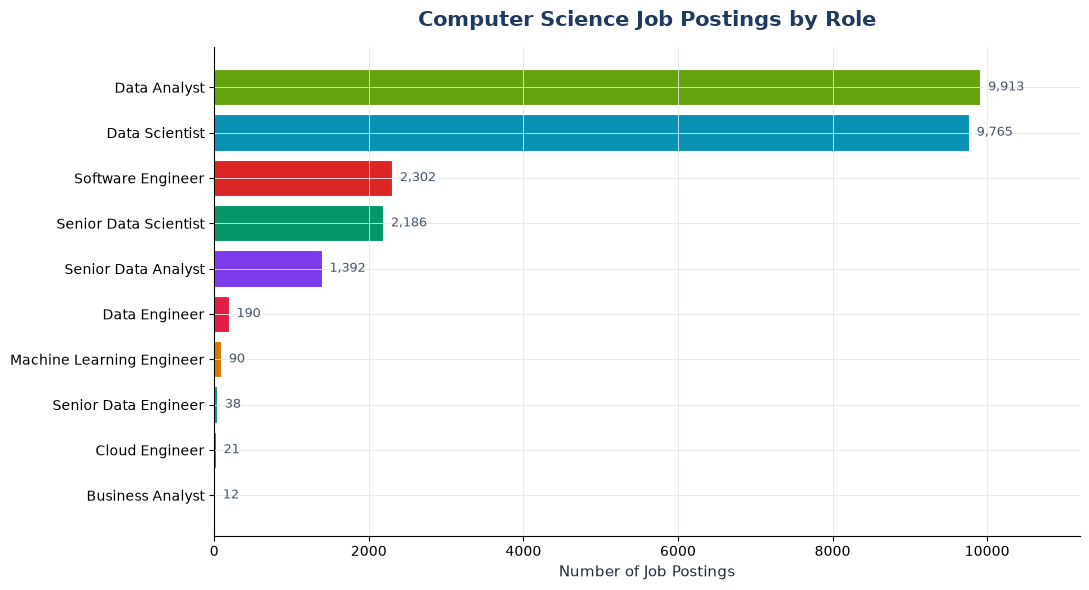

✅ Chart saved to charts/


In [ ]:
title_counts = df_raw['job_title_short'].value_counts()

fig, ax = plt.subplots(figsize=(11, 6))
bars = ax.barh(title_counts.index[::-1], title_counts.values[::-1],
               color=[PALETTE[i % len(PALETTE)] for i in range(len(title_counts))],
               edgecolor=WHITE, linewidth=0.8)
for bar in bars:
    ax.text(bar.get_width() + title_counts.max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f'{bar.get_width():,.0f}', va='center', fontsize=9, color=SLATE)
ax.set_xlabel('Number of Job Postings', fontsize=11, color='#1E293B')
ax.set_title('Computer Science Job Postings by Role', fontsize=15, fontweight='bold', color=NAVY, pad=15)
ax.set_xlim(0, title_counts.max() * 1.13)
plt.tight_layout()
plt.savefig('charts/chart1_job_postings_by_title.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Chart saved to charts/')

---
##  Analysis 2 — Top 15 Most In-Demand Skills

Rank  Skill          Count    % of Postings
---------------------------------------------
1     python          15,007   57.9%
2     sql             14,224   54.9%
3     r                6,774   26.1%
4     tableau          5,952   23.0%
5     excel            5,853   22.6%
6     power bi         4,423   17.1%
7     aws              4,022   15.5%
8     sas              3,998   15.4%
9     azure            3,584   13.8%
10    spark            2,692   10.4%
11    java             2,302   8.9%
12    tensorflow       1,998   7.7%
13    pytorch          1,597   6.2%
14    pandas           1,558   6.0%
15    git              1,542   6.0%


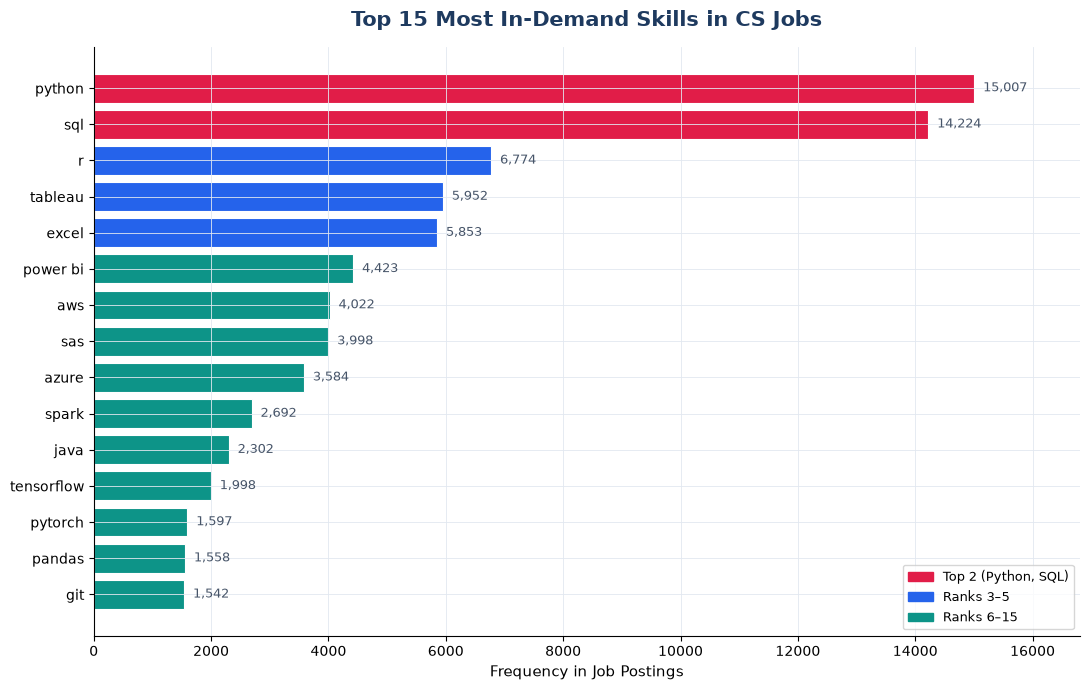

✅ Chart saved to charts/


In [ ]:
top15 = pd.Series(Counter(all_skills)).sort_values().tail(15)

# Print table
print('Rank  Skill          Count    % of Postings')
print('-' * 45)
for i, (skill, count) in enumerate(zip(top15.index[::-1], top15.values[::-1]), 1):
    pct = count / len(df) * 100
    print(f'{i:<5} {skill:<15} {count:>6,}   {pct:.1f}%')

# Chart
bar_colors = [ROSE if i >= 13 else BLUE if i >= 10 else TEAL for i in range(len(top15))]
fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(top15.index, top15.values, color=bar_colors, edgecolor=WHITE, linewidth=0.8)
for bar in bars:
    ax.text(bar.get_width() + top15.max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f'{bar.get_width():,.0f}', va='center', fontsize=9, color=SLATE)
ax.set_xlabel('Frequency in Job Postings', fontsize=11)
ax.set_title('Top 15 Most In-Demand Skills in CS Jobs', fontsize=15, fontweight='bold', color=NAVY, pad=15)
ax.set_xlim(0, top15.max() * 1.12)
legend_elems = [
    mpatches.Patch(color=ROSE, label='Top 2 (Python, SQL)'),
    mpatches.Patch(color=BLUE, label='Ranks 3–5'),
    mpatches.Patch(color=TEAL, label='Ranks 6–15'),
]
ax.legend(handles=legend_elems, fontsize=9, loc='lower right')
plt.tight_layout()
plt.savefig('charts/chart2_top15_skills_overall.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Chart saved to charts/')

---
##  Analysis 3 — Top Skills by Job Title (Individual Charts)

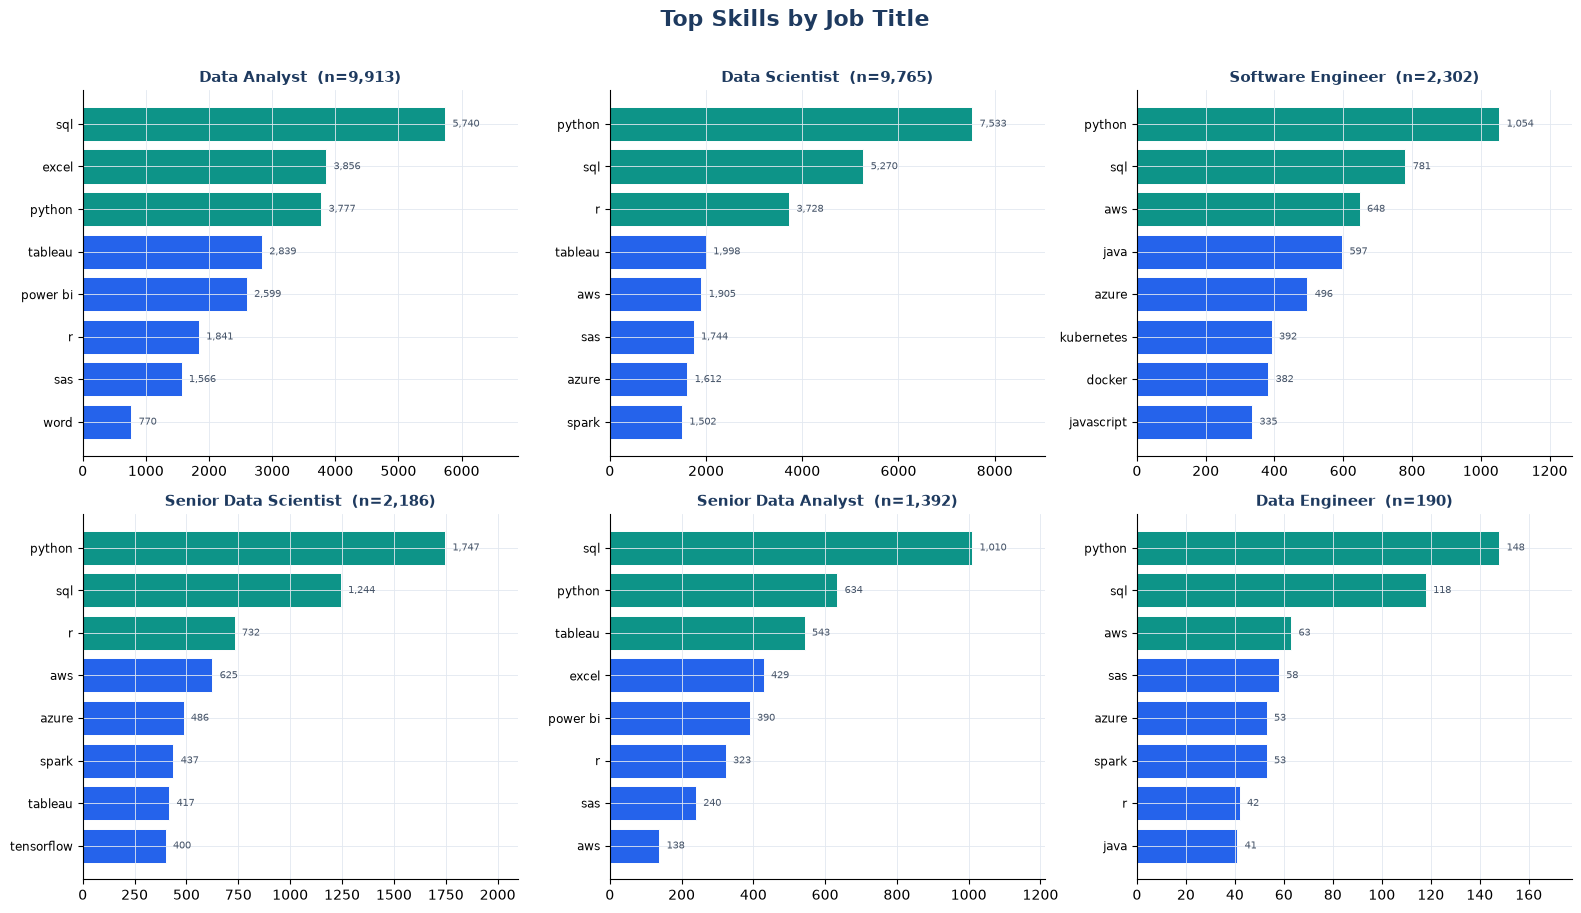

✅ Chart saved to charts/


In [ ]:
major_jobs = df['job_title_short'].value_counts().head(6).index.tolist()

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, job in zip(axes.flat, major_jobs):
    skills = [sk for lst in df.loc[df['job_title_short'] == job, 'skills_list'] for sk in lst]
    top8 = pd.Series(Counter(skills)).sort_values().tail(8)
    bar_colors = [BLUE if i < 5 else TEAL for i in range(len(top8))]
    ax.barh(top8.index, top8.values, color=bar_colors, edgecolor=WHITE, linewidth=0.7)
    for j, v in enumerate(top8.values):
        ax.text(v + top8.max() * 0.02, j, f'{v:,.0f}', va='center', fontsize=7.5, color=SLATE)
    n = df['job_title_short'].eq(job).sum()
    ax.set_title(f'{job}  (n={n:,})', fontsize=11, fontweight='bold', color=NAVY)
    ax.tick_params(axis='y', labelsize=8.5)
    ax.set_xlim(0, top8.max() * 1.2)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.suptitle('Top Skills by Job Title', fontsize=16, fontweight='bold', color=NAVY, y=1.01)
plt.tight_layout()
plt.savefig('charts/chart3_top_skills_by_job_title.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Chart saved to charts/')

---
##  Analysis 4 — Skill Categories

Category             Total Mentions
-----------------------------------
Programming              34,907
Database                 22,018
Visualization / BI       17,722
Cloud                     8,891
Big Data                  7,718
AI / ML                   5,463
DevOps / Containers       3,359
Version Control           2,539


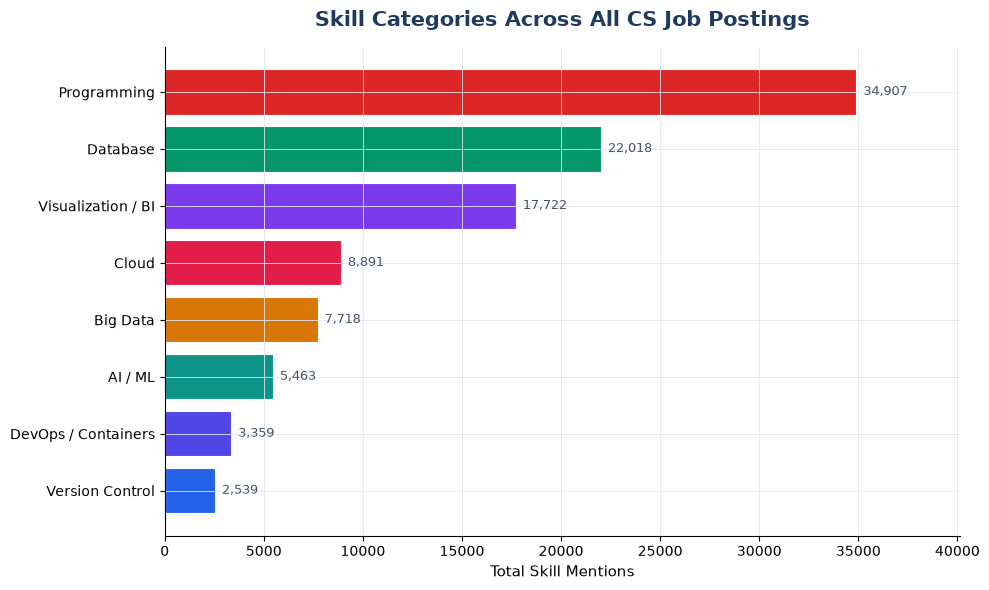

✅ Chart saved to charts/


In [ ]:
SKILL_CATEGORIES = {
    'Programming':         ['python', 'java', 'r', 'c', 'c++', 'javascript', 'scala', 'go', 'ruby', 'php', 'c#', 'sas', 'matlab'],
    'Database':            ['sql', 'mysql', 'postgresql', 'mongodb', 'oracle', 'nosql', 'sql server', 'redshift', 'bigquery', 'snowflake'],
    'Cloud':               ['aws', 'azure', 'gcp', 'google cloud'],
    'Visualization / BI':  ['tableau', 'power bi', 'looker', 'qlik', 'excel'],
    'Version Control':     ['git', 'github', 'gitlab', 'bitbucket'],
    'Big Data':            ['spark', 'hadoop', 'kafka', 'pyspark', 'airflow', 'databricks'],
    'AI / ML':             ['tensorflow', 'pytorch', 'scikit-learn', 'keras', 'sklearn'],
    'DevOps / Containers': ['docker', 'kubernetes', 'jenkins', 'terraform', 'ansible'],
}

skill_freq = Counter(all_skills)
cat_totals = pd.Series({
    cat: sum(skill_freq.get(s, 0) for s in skills)
    for cat, skills in SKILL_CATEGORIES.items()
}).sort_values()

# Print table
print('Category             Total Mentions')
print('-' * 35)
for cat, total in cat_totals.sort_values(ascending=False).items():
    print(f'{cat:<22} {total:>8,}')

# Chart
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(cat_totals.index, cat_totals.values,
               color=PALETTE[:len(cat_totals)], edgecolor=WHITE, linewidth=0.8)
for bar in bars:
    ax.text(bar.get_width() + cat_totals.max() * 0.01,
            bar.get_y() + bar.get_height() / 2,
            f'{bar.get_width():,.0f}', va='center', fontsize=9, color=SLATE)
ax.set_xlabel('Total Skill Mentions', fontsize=11)
ax.set_title('Skill Categories Across All CS Job Postings', fontsize=15, fontweight='bold', color=NAVY, pad=15)
ax.set_xlim(0, cat_totals.max() * 1.15)
plt.tight_layout()
plt.savefig('charts/chart4_skill_categories.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Chart saved to charts/')

---
##  Analysis 5 — Skills by Country

Country              Rank 1       Rank 2       Rank 3       Rank 4       Rank 5
---------------------------------------------------------------------------
United States        sql           python        r             tableau       excel       
United Kingdom       python        sql           excel         r             power bi    
India                python        sql           r             tableau       excel       
France               python        sql           power bi      sas           r           
Germany              python        sql           r             tableau       power bi    


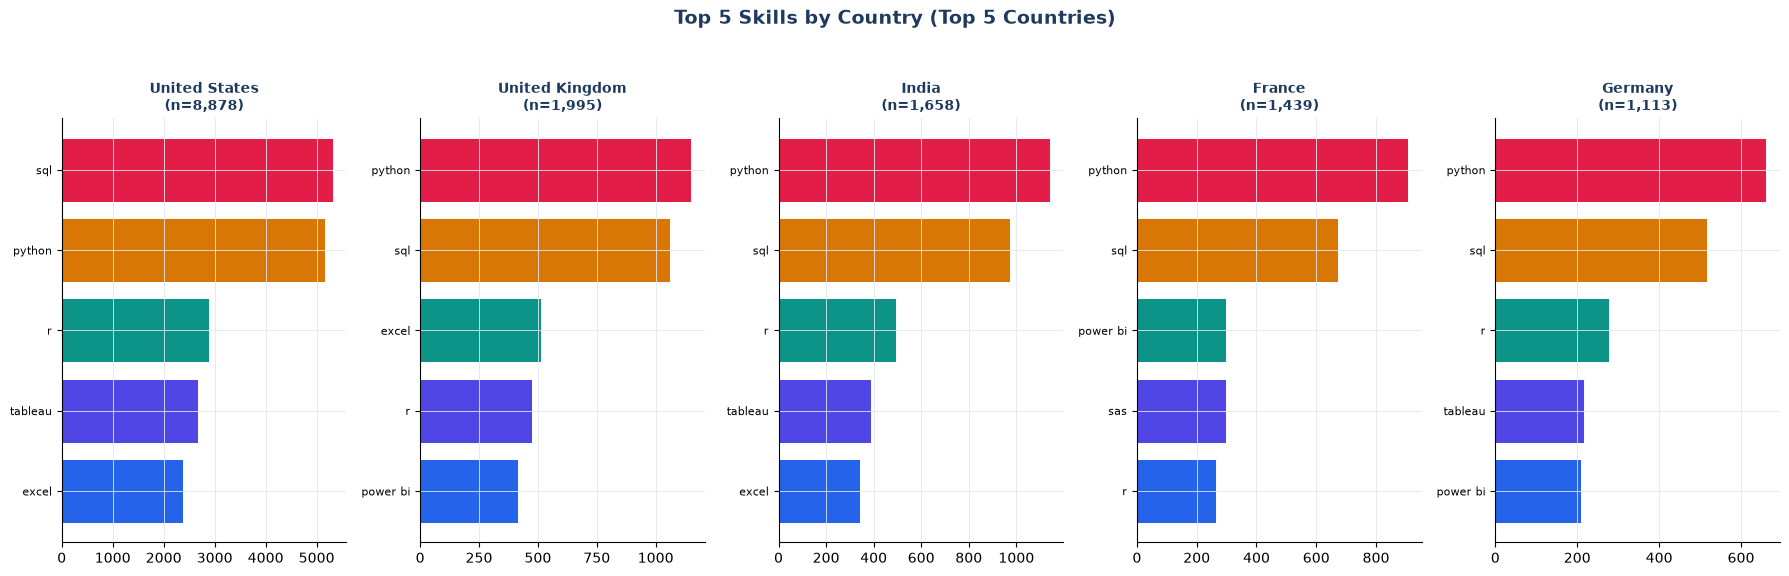

✅ Chart saved to charts/


In [ ]:
top_countries = df['job_country'].value_counts().head(5).index.tolist()

# Print table
print(f'{"Country":<20} {"Rank 1":<12} {"Rank 2":<12} {"Rank 3":<12} {"Rank 4":<12} {"Rank 5"}')
print('-' * 75)
for country in top_countries:
    skills = [sk for lst in df.loc[df['job_country'] == country, 'skills_list'] for sk in lst]
    top5 = [sk for sk, _ in Counter(skills).most_common(5)]
    print(f'{country:<20}', '  '.join(f'{s:<12}' for s in top5))

# Chart
fig, axes = plt.subplots(1, 5, figsize=(18, 5.5))
for ax, country in zip(axes, top_countries):
    skills = [sk for lst in df.loc[df['job_country'] == country, 'skills_list'] for sk in lst]
    top5 = pd.Series(Counter(skills)).sort_values().tail(5)
    ax.barh(top5.index, top5.values, color=PALETTE[:5], edgecolor=WHITE, linewidth=0.7)
    n = df['job_country'].eq(country).sum()
    ax.set_title(f'{country}\n(n={n:,})', fontsize=10, fontweight='bold', color=NAVY)
    ax.tick_params(axis='y', labelsize=8)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

fig.suptitle('Top 5 Skills by Country (Top 5 Countries)', fontsize=14, fontweight='bold', color=NAVY, y=1.04)
plt.tight_layout()
plt.savefig('charts/chart5_skills_by_country.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Chart saved to charts/')

---
##  Analysis 6 — Average Salary by Job Title

Job Title                        Avg Salary  Data Points Confidence
-----------------------------------------------------------------
Senior Data Scientist          $   153,518          142   High
Machine Learning Engineer      $   126,550            1   Low
Data Scientist                 $   119,949          626   High
Business Analyst               $   118,500            1   Low
Software Engineer              $   113,218           42   Medium
Senior Data Analyst            $   111,682           87   High
Data Engineer                  $    92,508            7   Low
Data Analyst                   $    86,131          664   High


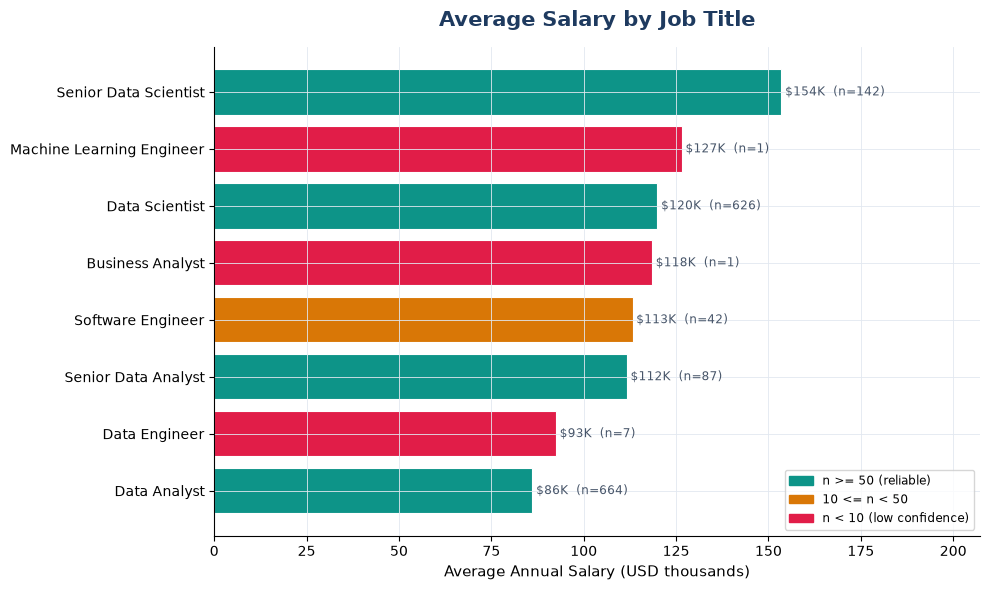

✅ Chart saved to charts/


In [ ]:
sal_by_job = df_sal.groupby('job_title_short')['salary_year_avg'].agg(['mean', 'count']).sort_values('mean')

# Print table
print(f'{"Job Title":<30} {"Avg Salary":>12} {"Data Points":>12} {"Confidence"}')
print('-' * 65)
for job, row in sal_by_job.sort_values('mean', ascending=False).iterrows():
    conf = 'High' if row['count'] >= 50 else ('Medium' if row['count'] >= 10 else 'Low')
    print(f'{job:<30} ${row["mean"]:>10,.0f} {int(row["count"]):>12}   {conf}')

# Chart
fig, ax = plt.subplots(figsize=(10, 6))
bar_colors = [TEAL if c >= 50 else AMBER if c >= 10 else ROSE for c in sal_by_job['count']]
bars = ax.barh(sal_by_job.index, sal_by_job['mean'] / 1000, color=bar_colors, edgecolor=WHITE, linewidth=0.8)
for bar, n in zip(bars, sal_by_job['count']):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f'${bar.get_width():.0f}K  (n={n})', va='center', fontsize=8.5, color=SLATE)
ax.set_xlabel('Average Annual Salary (USD thousands)', fontsize=11)
ax.set_title('Average Salary by Job Title', fontsize=15, fontweight='bold', color=NAVY, pad=15)
ax.set_xlim(0, sal_by_job['mean'].max() / 1000 * 1.35)
legend_elems = [
    mpatches.Patch(color=TEAL,  label='n >= 50 (reliable)'),
    mpatches.Patch(color=AMBER, label='10 <= n < 50'),
    mpatches.Patch(color=ROSE,  label='n < 10 (low confidence)'),
]
ax.legend(handles=legend_elems, fontsize=8.5, loc='lower right')
plt.tight_layout()
plt.savefig('charts/chart6_avg_salary_by_job_title.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Chart saved to charts/')

---
##  Analysis 7 — Average Number of Skills Required per Job

Job Title                      Avg Skills Required
--------------------------------------------------
Senior Data Engineer           7.8
Data Engineer                  7.8
Machine Learning Engineer      6.0
Software Engineer              6.0
Senior Data Scientist          5.7
Data Scientist                 5.4
Cloud Engineer                 5.4
Senior Data Analyst            4.5
Business Analyst               4.2
Data Analyst                   4.0


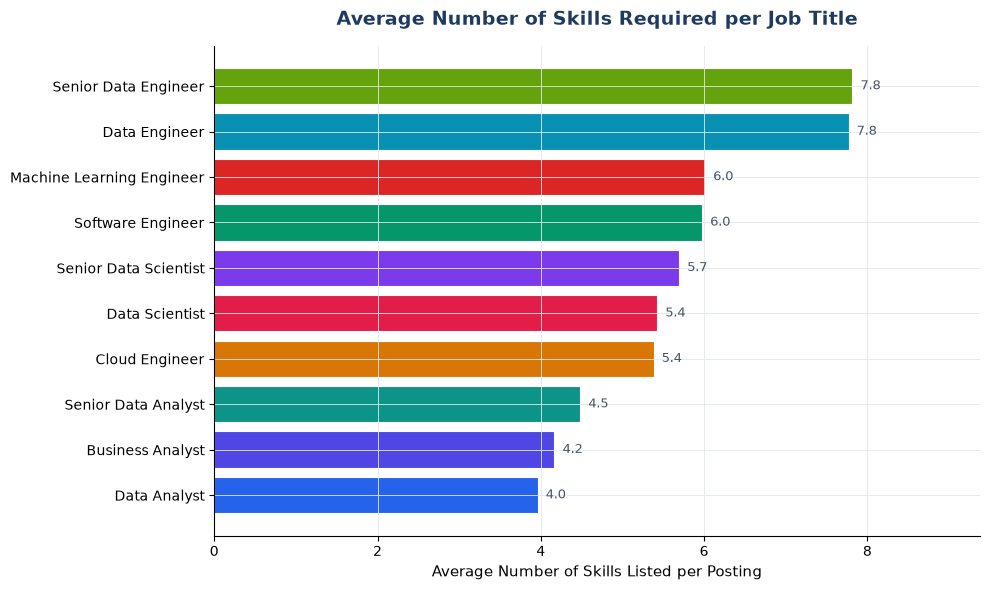

✅ Chart saved to charts/


In [ ]:
df['n_skills'] = df['skills_list'].map(len)
avg_skills = df.groupby('job_title_short')['n_skills'].mean().sort_values()

# Print table
print(f'{"Job Title":<30} {"Avg Skills Required"}')
print('-' * 50)
for job, avg in avg_skills.sort_values(ascending=False).items():
    print(f'{job:<30} {avg:.1f}')

# Chart
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(avg_skills.index, avg_skills.values,
               color=PALETTE[:len(avg_skills)], edgecolor=WHITE, linewidth=0.8)
for bar in bars:
    ax.text(bar.get_width() + 0.1, bar.get_y() + bar.get_height() / 2,
            f'{bar.get_width():.1f}', va='center', fontsize=9, color=SLATE)
ax.set_xlabel('Average Number of Skills Listed per Posting', fontsize=11)
ax.set_title('Average Number of Skills Required per Job Title',
             fontsize=14, fontweight='bold', color=NAVY, pad=15)
ax.set_xlim(0, avg_skills.max() * 1.2)
plt.tight_layout()
plt.savefig('charts/chart10_avg_skills_per_job.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Chart saved to charts/')

---
## 🎯 Key Findings & Learning Roadmap

### Key Findings
1. **Data Analyst (38.3%) and Data Scientist (37.7%)** together make up over 76% of all postings
2. **Python (57.9%) and SQL (54.9%)** appear in over half of all job postings — the most universal CS skills
3. **Analyst roles** favour Excel, Tableau, and Power BI alongside SQL
4. **Engineering roles** favour AWS, Azure, Kubernetes — and require nearly double the skills (7.8 vs 4.0)
5. **Senior Data Scientist** has the highest average salary ($153,518)
6. **Specialist skills** (PyTorch, TensorFlow, Spark, GCP) pay significantly more than general skills
7. **Python and SQL lead in every country** studied — geography matters far less than role

---

### 🗺️ Learning Roadmap by Career Path

**If you want to become a Data Analyst:**
1. SQL — required in 58% of Data Analyst postings
2. Excel — present in 39% of postings
3. Python — present in 38% of postings
4. Tableau — the leading BI visualisation tool (29%)
5. Power BI — the second most common BI tool (26%)

**If you want to become a Data Scientist:**
1. Python — required in 77% of Data Scientist postings
2. SQL — required in 54% of postings
3. R — a strong secondary language (38%)
4. Tableau — for visualisation
5. AWS — for cloud/model deployment (20%)

**If you want to become a Software Engineer:**
1. Python — the leading language (46%)
2. SQL — for application data (34%)
3. AWS — the dominant cloud platform (28%)
4. Java — still widely required (26%)
5. Docker + Kubernetes — containerisation

**If you want to become a Data Engineer:**
1. Python + SQL — the foundation
2. AWS — leading cloud platform for data infrastructure
3. Spark — for large-scale data processing
4. Docker + Kubernetes — orchestration
5. Note: Engineers average 7.8 skills per posting — the broadest role

**If you want to become a Machine Learning Engineer:**
1. Python — the foundation
2. PyTorch + TensorFlow — the two leading deep learning frameworks
3. SQL — for data pipelines
4. Azure or AWS — for model deployment
5. Scikit-learn + Pandas — top salary-boosting libraries